# Why Some Students Use AI More Than Others

## Topic Overview

AI tools have become a common resource for students when completing homework and studying. However, students use AI differently depending on their study habits, academic pressure, and personal preferences. Some students use AI to understand concepts or review mistakes, while others rely on it to complete assignments when they have limited time. Others might prefer to not use it all, whether that be because their classes prohibit its use or just so they understand the content better.  

Our project investigates why some students use AI more frequently than others. We explore how factors such as deadline pressure, procrastination, stress, and personal concerns relate to students' AI usage. By analyzing survey responses, we hope to better understand when students choose to use AI, what they use it for, and what might discourage or encourage them from using it.


## Q1: What data do we have?

Our dataset comes from a survey conducted among students in CS105 and CS111 classes. The survey includes questions about students' AI usage, homework habits, procrastination, academic stress, and reasons that might prevent them from using AI.  

We mainly focus on questions about how frequently students use AI for different study activities, how they approach homework under different deadline conditions, and how they feel about using AI for academic work. We also examine students' reported stress levels, procrastination habits, and class standing.  

To prepare the dataset, we selected the relevant survey questions, handled missing responses, and converted certain categorical responses into numerical values when necessary. We then used these data to create visualizations and perform statistical tests to identify patterns and relationships in students' AI usage.


## Q2: What would we like to know?

Our main goal is to understand why some students rely on AI more frequently than others and what factors influence their decisions to use AI for schoolwork.  

Specifically, we want to investigate the following questions:
1. What academic activities do students use AI for most frequently, and what reasons discourage them from using AI?
2. How do deadline pressure and procrastination relate to students' reliance on AI when completing homework?
3. Do students who experience more academic stress tend to use AI more frequently or prefer AI over asking their professor or TA for help?
4. Are students' attitudes toward AI associated with their actual usage habits, and do these patterns differ across students?  

Through our visualizations and hypothesis tests, we hope to identify the major factors associated with students' AI usage and better understand how AI fits into their academic routines.


## Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Rectangle, Patch
from matplotlib.lines import Line2D
from pathlib import Path
import plotly.graph_objects as go
from scipy.stats import spearmanr
from scipy import stats

df = pd.read_csv("../../data/uncleaned_data.csv")

# answers use a curly apostrophe (’), swap it for a normal one (')
df = df.replace("’", "'", regex=True)

## Data Cleaning

### Visualization 1

To compare students we needed one number for how much each student uses AI (AI-reliance score).

- [CA]–[CH] "How often do you use AI for the following" asked about 8 tasks, each with 4 options (I don't use AI for this | I use it rarely | I use it sometimes | I use it very often).  
Each becomes a value 0–3 and averaged them, so each student gets one **AI-reliance score** from 0 (never) to 3 (very often). Blanks and "Prefer not to answer" were skipped.

We then focused on the questions that put these students into the different groups that we will be observing.

- [DE] "I want to learn the material myself," [DG] "I don't trust its answers," and [DH] "My class rules don't allow it".  
Each had 4 options (Not at all | A little | Somewhat | A lot).  
"Not at all" and "A little" were small groups so they got combined. "Somewhat" and "A lot" were left as is.

In [2]:
# Visualization 1
df_1 = df.copy()

# look through the df to find the 8 "how often do you use AI for..." columns
ai_cols = [c for c in df_1.columns if c.startswith("How often do you use AI for the following:")]

# look through the df to find the 3 reason columns
learn_col = [c for c in df_1.columns if "learn the material myself" in c][0]
trust_col = [c for c in df_1.columns if "trust its answers" in c][0]   # "don't trust its answers"
rules_col = [c for c in df_1.columns if "class rules" in c][0]

# turn each ai use answer into a number, anything else (blank, prefer not to answer) becomes NaN
to_number = {
    "I don't use AI for this": 0,
    "I use it rarely": 1,
    "I use it sometimes": 2,
    "I use it very often": 3,
}
numbers = pd.DataFrame()
for col in ai_cols:
    numbers[col] = df_1[col].map(to_number)

# break down the groups like stated in the above markdown cell
reason_groups = {
    "Not at all": "Not at all / A little",
    "A little": "Not at all / A little",
    "Somewhat": "Somewhat",
    "A lot": "A lot",
}

# One row per student with their reliance score (average of the 8 numbers, NaNs skipped) and their three grouped answers.
# NaNs are kept here, seaborn drops them for each panel on its own.
data_1 = pd.DataFrame({
    "reliance_score": numbers.mean(axis=1),
    "learn_myself": df_1[learn_col].map(reason_groups),
    "no_trust": df_1[trust_col].map(reason_groups),
    "class_rules": df_1[rules_col].map(reason_groups),
})

### Visualization 2

We created groups for stressed/less-stressed students and groups (based on score) for how often students consulted AI before professor/TA.

- [FI]–[FK]: For the question about consulting AI, there were 3 tasks that had choices (Never | Rarely | Sometimes | Often | All the time). Those choices were then converted into values 0-4 and averaged per student. Again we grouped students into buckets based on that averaged score.
    - Rarely: ($0 \le$ score $\le 1$) (mostly Never / Rarely)
    - Sometimes: ($1 \lt$ score $\le 2$)
    - Often: ($2 \lt$ score) (mostly Often / All the time)

- [FG]: The single question that we used to determine stress [FG] had values 1-5. Since the upper and lower ends had few students we grouped them into less stress (1-3) and very stress (4-5).

In [3]:
# Visualization 2
df_2 = df.copy()

# look through the df to find the 3 "AI without your professor or TA" columns and the stress column
skip_cols_2 = [c for c in df_2.columns if "without consulting your professor or TA" in c]
stress_col = [c for c in df_2.columns if "[Stress about coursework]" in c][0]

# turn each answer into a number, anything else (blank, prefer not to answer) becomes NaN
to_number = {"Never": 0, "Rarely": 1, "Sometimes": 2, "Often": 3, "All the time": 4}
numbers_2 = pd.DataFrame()
for col in skip_cols_2:
    numbers_2[col] = df_2[col].map(to_number)

# break down the groups like stated in the above markdown cell
ai_instead = pd.cut(numbers_2.mean(axis=1), bins=[-1, 1, 2, 4], labels=["Rarely", "Sometimes", "Often"])
stress_2 = pd.cut(pd.to_numeric(df_2[stress_col], errors="coerce"), bins=[0, 3, 5],
                labels=["Less stressed (1-3)", "Very stressed (4-5)"])

# One row per student. Drop students who skipped either question.
data_2 = pd.DataFrame({
    "ai_instead": ai_instead,
    "stress": stress_2,
}).dropna()

### Visualization 3

- Keep survey questions that are AI usage after Procrastinating and number of days AI is used per week
- trim spaces from text and keep any missing responses as missing
- convert the Procrastination values to numerical values Never = 1, Always = 5.
- Separate numerical columns for statistical analysis
- For spearman correlation test make sure they answer both questions not just one

In [4]:
#Visual 3 data cleaning
# Keep the original dataset unchanged
df_3 = df.copy()

# Create analysis dataframe
df_sankeyAnalysis_3 = pd.DataFrame()

df_sankeyAnalysis_3["ai_days"] = pd.to_numeric(df_3[next(col for col in df_3.columns if "on how many days did you use AI tools for schoolwork" in col)],errors="coerce")

df_sankeyAnalysis_3["ai_minutes"] = pd.to_numeric(df_3[next(col for col in df_3.columns if "Total minutes:" in col)],errors="coerce")

df_sankeyAnalysis_3["main_reason"] = df_3[next(col for col in df_3.columns
if "main reason for using AI" in col)]

df_sankeyAnalysis_3["reliance_after_procrastinating"] = df_3[next(col for col in df_3.columns
if "I find myself relying on AI more after I procrastinate" in col)]

df_sankeyAnalysis_3["homework_timing"] = df_3[next(col for col in df_3.columns
if "How far in advance do you typically begin working" in col
and "[Homework]" in col)]

df_sankeyAnalysis_3["coursework_stress"] = pd.to_numeric(df_3[next(col for col in df_3.columns
if "[Stress about coursework]" in col)],errors="coerce")

# Clean text columns
text_columns = ["main_reason","reliance_after_procrastinating","homework_timing"]

for col in text_columns:
    df_sankeyAnalysis_3[col] = df_sankeyAnalysis_3[col].str.strip()

### Visualization 4

For the heatmap, we first loaded the original uncleaned_data.csv dataset using pandas. We selected only the eight survey questions related to how frequently students use AI for different study activities, such as reviewing lecture slides, completing homework, reviewing mistakes, and asking questions.

Next, we used value_counts() to count how many students selected each response for every study activity. We then combined these counts into a new DataFrame using pd.DataFrame() and transposed it so that each row represented a study activity and each column represented an AI usage frequency.

We used fillna(0) to replace missing response counts with zero and reindex() to arrange the five frequency categories in a consistent order, from "I use it very often" to "Prefer not to answer" so it follows our original google form. Then we divided each response count by the total number of responses for that activity and multiplied by 100 to convert the counts into percentages.

This preparation allowed us to compare AI usage frequencies across all eight study activities using a heatmap.

Add on to correlation test:
For the correlation test, we selected two study activities from the heatmap dataset: asking questions and reviewing calculation mistakes. We converted the frequency responses into numerical values from 0 to 3, where 0 represents not using AI and 3 represents using AI very often.

We then combined the two variables into a new DataFrame and used dropna() to remove students with missing or non-frequency responses for either activity. This produced 83 valid paired responses for the Spearman correlation analysis.

In [5]:
#Visual 4 data cleaning

df_4 = df.copy()
# create crosstable that limit x-axis as "i don't use AI for this, i use it rarely, etc"
# y-axis as types of questions: "reviewing lecture slides, doing homework for STEM related subjects, etc"
study_cols = [c for c in df_4.columns if c.startswith("How often do you use AI for the following:")]
study_df_4 = df_4[study_cols]

# Count responses for each study activity
lecture = study_df_4.iloc[:, 0].value_counts()
coding = study_df_4.iloc[:, 1].value_counts()
stem = study_df_4.iloc[:, 2].value_counts()
writing = study_df_4.iloc[:, 3].value_counts()
calculation = study_df_4.iloc[:, 4].value_counts()
written_review = study_df_4.iloc[:, 5].value_counts()
questions = study_df_4.iloc[:, 6].value_counts()
definitions = study_df_4.iloc[:, 7].value_counts()

# Combine response counts into one DataFrame
cross_survey = pd.DataFrame({
    "Reviewing Lecture Slides": lecture,
    "Coding Assignments": coding,
    "STEM Homework": stem,
    "Writing Assignments": writing,
    "Calculation Mistakes": calculation,
    "Written Mistakes": written_review,
    "Asking Questions": questions,
    "Asking Definitions": definitions
}).T.fillna(0)

# Reorder the response categories
response_order = ["I use it very often", "I use it sometimes", "I use it rarely", "I don't use AI for this", "Prefer not to answer"]

cross_survey = cross_survey.reindex(columns=response_order, fill_value=0)

# Calculate percentages
percentage_survey_4 = (cross_survey.div(cross_survey.sum(axis=1), axis=0) * 100)

### Visualization 5

For the stacked bar chart, we loaded the original uncleaned_data.csv dataset and selected only the three survey questions about students' preferred homework strategies under different deadline conditions: more than enough time, just enough time, and not enough time.

We used value_counts() to count the responses for each deadline situation and combined the counts into one DataFrame. Each row represented a different deadline condition, while each column represented a homework strategy, such as trying independently, asking a classmate or TA, asking AI for hints or explanations, asking AI for a complete solution, or leaving the problem incomplete.

Next, we used fillna(0) to replace missing response counts with zero and reindex() to arrange the homework strategies in a consistent order. We then divided each response count by the total responses for that deadline condition and multiplied by 100 to calculate the percentages.

This preparation ensured that each deadline condition totaled 100%, allowing us to compare the distribution of homework strategies using a 100% stacked bar chart.

In [6]:
#Visual 5 data cleaning
df_5 = df.copy()

# Clean up the data by selecting the three homework strategy questions
homework_df = df_5.loc[:, "If you have been working on a homework problem for 15 minutes without making any progress, what action are you most likely to take in each of the following scenarios? [When you have more than enough time to finish your assignment before the deadline]" : "If you have been working on a homework problem for 15 minutes without making any progress, what action are you most likely to take in each of the following scenarios? [When you don’t have enough time to finish your assignment before the deadline]"]

# Count the responses for each deadline situation
more_time = homework_df.iloc[:, 0].value_counts()
just_enough = homework_df.iloc[:, 1].value_counts()
not_enough = homework_df.iloc[:, 2].value_counts()

# Combine the counts into one DataFrame
cross_homework = pd.DataFrame({
    "More than enough time": more_time,
    "Just enough time": just_enough,
    "Not enough time": not_enough
}).T

# Replace missing response with 0
cross_homework = cross_homework.fillna(0)

# Set the order of homework strategies
strategy_order = [
    "Trying on my own",
    "Seek help from a classmate or TA",
    "Ask AI for a hint or explanation",
    "Ask AI for the complete solution",
    "Leave the problem as incomplete"
]

# Reorder the columns
cross_homework = cross_homework.reindex(columns=strategy_order, fill_value=0)


# Calculate the percentage of each homework strategy for each deadline situation
# Divide each count by the total responses in its row
percentage_homework_5 = cross_homework.div(cross_homework.sum(axis=1), axis=0) * 100

### Visualization 6

Here I pulled data from three questions: how much users agree AI decreased stress, their actual stress levels, and the amount of AI used in the last 7 days. I numerized the response on the scale from strong disagree to strong agree from 1-5 to plot it on the graph. I bubbled similar answers together for the question of if they agreed AI decreased stress and plotted it with the x-axis representing the stress levels and y-axis representing the amount of AI used in the last 7 days.

In [7]:
#Visual 6 data cleaning
df_6 = df.copy()

cols = list(df_6.columns)
help_col = [c for c in cols if "AI has helped me feel less stressed" in c][0]
agree_scale = {"Strong disagree": 1, "Disagree": 2, "Neutral": 3, "Agree": 4, "Strong agree": 5}
group_names = {1: "Strongly\ndisagree", 2: "Disagree", 3: "Neutral", 4: "Agree", 5: "Strongly\nagree"}

stress_col = [c for c in cols if "past 7 days how much did you experience" in c and "Stress about coursework" in c][0]
minutes_col = [c for c in cols if c.startswith("In the past 7 days, approximately how many minutes")][0]

df_6 = pd.DataFrame({
    "help": df_6[help_col].astype(str).str.strip().map(agree_scale),
    "stress": pd.to_numeric(df_6[stress_col], errors="coerce"),
    "minutes": pd.to_numeric(df_6[minutes_col], errors="coerce"),
}).dropna()

# One bubble per answer group
groups_6 = sorted(df_6["help"].unique())
stress_avg_6 = [df_6.loc[df_6.help == g, "stress"].mean() for g in groups_6] 
minutes_med_6 = [df_6.loc[df_6.help == g, "minutes"].median() for g in groups_6]
students_6 = [int((df_6.help == g).sum()) for g in groups_6]
labels_6 = [group_names[int(g)] for g in groups_6]
colors = {1: "#d7191c", 2: "#fdae61", 3: "#ffffbf", 4: "#abd9e9", 5: "#2c7bb6"}
bubble_colors_6 = [colors[int(g)] for g in groups_6]

for lab, n, x_, y_ in zip(labels_6, students_6, stress_avg_6, minutes_med_6):
    print(f"{lab.replace(chr(10), ' '):<20} n={n:<3} avg stress={x_:.2f}  median minutes={y_:.0f}")

Strongly disagree    n=9   avg stress=3.11  median minutes=0
Disagree             n=5   avg stress=2.60  median minutes=60
Neutral              n=22  avg stress=3.59  median minutes=35
Agree                n=30  avg stress=4.00  median minutes=120
Strongly agree       n=12  avg stress=4.17  median minutes=120


### Visualization 7

Here I pulled data from multiple different sources. Specifically the survey questions that inquired about different amounts of procrastination from working on other to assignments to gaming or watching shows. Afterwards, I separated them into different columns and turned the responses into numerical values I could plot on the graphs. I then pulled data from how many minutes of AI used in the last 7 days to create the buckets for in increments of 50 minutes. For the last touch, I added an overall total procrastination column at the end to track overall procrastination. I did additionally remove any responses that either did not answer the survey questions or had minutes of AI use that seemed like outliers (answers over 400 minutes).

In [8]:
#Visual 7 data cleaning
df_7 = df.copy()

proc_df = df_7.loc[:, "If you procrastinate, what do you typically spend your time doing?  [Sleeping/Napping]":
                           "If you procrastinate, what do you typically spend your time doing?  [Gaming]"].copy()
proc_df.columns = ["Sleeping/\nNapping", "Hanging Out\nwith Friends", "Easier\nAssignments", "Shows/\nMovies", "Social\nMedia", "Gaming"]

minutes_col = [c for c in df_7.columns if c.startswith("In the past 7 days, approximately how many minutes")][0]
ai_col = "Average Minutes\nof AI Used"
raw_ai_col = "raw_minutes"
proc_df[raw_ai_col] = pd.to_numeric(df_7[minutes_col], errors="coerce")

# Convert the answers into values 1 to 5
scale = {"Never": 1, "Rarely": 2, "Sometimes": 3, "Often": 4, "Always": 5}
procrastination_types = [c for c in proc_df.columns if c != raw_ai_col]
for col in procrastination_types:
    proc_df[col] = proc_df[col].map(scale)

# Remove rows with blank values
proc_df = proc_df.dropna()


ai_cutoff_7 = 400
n_before = len(proc_df)
proc_df = proc_df[proc_df[raw_ai_col] <= ai_cutoff_7]
n_removed_7 = n_before - len(proc_df)


overall_col = "Overall\nProcrastination"
proc_df[overall_col] = proc_df[procrastination_types].mean(axis=1)


bucket_size_7 = 50
edges = list(range(0, ai_cutoff_7 + 1, bucket_size_7))
bucket_labels = [f"{lo + 1}-{hi} min" for lo, hi in zip(edges[:-1], edges[1:])]
proc_df["bucket"] = pd.cut(proc_df[raw_ai_col], bins=edges, labels=bucket_labels, include_lowest=True)


value_cols = [raw_ai_col] + procrastination_types + [overall_col]
bucket_means = proc_df.groupby("bucket", observed=True)[value_cols].mean()
bucket_n_7 = proc_df.groupby("bucket", observed=True).size()
bucket_means = bucket_means.rename(columns={raw_ai_col: ai_col})


ai_ticks_7 = [0, 100, 200, 300, 400]

scaled_df_7 = pd.DataFrame(index=bucket_means.index)
scaled_df_7[ai_col] = bucket_means[ai_col] / ai_cutoff_7
for col in procrastination_types + [overall_col]:
    scaled_df_7[col] = (bucket_means[col] - 1) / 4

columns_7 = [ai_col] + procrastination_types + [overall_col]
x_7 = np.arange(len(columns_7))

# One color per bucket (light to dark as AI use goes up)
cmap = plt.cm.viridis
bucket_colors_7 = {b: cmap(0.05 + 0.85 * i / (len(bucket_labels) - 1)) for i, b in enumerate(bucket_labels)}

### Visualization 8

- Keep the six homework-deterrent questions and class standing. Trim spaces and keep blanks as missing.
- Code Not at all = 0, A little = 1, Somewhat = 2, and A lot = 3. Flag unexpected answers.
- For the radar chart, keep Freshman–Senior and use valid answers per item. Exclude the one concurrent response from this chart.
- For paired tests, require all four score items. Average independent learning and future independence for the learning score; average distrust and difficulty using AI for the trust/skill score.
- For the chi-squared test, require both class-rule and cheating answers. Group scores 0–1 as Lower and 2–3 as Higher.

In [9]:
#Visual 8 data cleaning

# Locate the repository whether launched from this folder or the repository root.
repo_root = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / 'data' / "uncleaned_data.xlsx").is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError('Could not locate data/uncleaned_data.xlsx in the repository.')
source_path = repo_root / 'data' / "uncleaned_data.xlsx"
output_dir_8 = repo_root / 'working_folders' / 'slian088'

df_8 = df.copy()

factors_8 = {
    'learn_myself': ('DE', 'I want to learn the material myself'),
    'future_independence': ('DF', 'I need to be able to do it without AI later'),
    'distrust_answers': ('DG', 'I don’t trust its answers'),
    'class_rules': ('DH', "My class rules don't allow it"),
    'feels_like_cheating': ('DI', 'I feel like I am cheating'),
    'lack_of_ai_skills': ('DJ', "I don't know how to use it well"),
}
selected = {}
for short_name, (excel_col, wording) in factors_8.items():
    matches = [c for c in df_8.columns
               if c.startswith('When you are working on a homework assignment,')
               and c.strip().endswith(f'[{wording}]')]
    if len(matches) != 1:
        raise ValueError(f'Expected exactly one column for {short_name}: {matches}')
    selected[matches[0]] = short_name

raw_factors = df_8[list(selected)].rename(columns=selected).copy()
raw_factors.index = pd.RangeIndex(2, len(df_8) + 2, name='source_excel_row')
variable_dictionary = pd.DataFrame([
    {'variable': name, 'original_excel_column': col, 'factor': wording}
    for name, (col, wording) in factors_8.items()
])
print(variable_dictionary.to_string(index=False))
print('\nFirst five responses (original text):')
print(raw_factors.head().to_string())

score_map = {'Not at all': 0, 'A little': 1, 'Somewhat': 2, 'A lot': 3}
text_factors = raw_factors.apply(lambda col: col.astype('string').str.strip())
text_factors = text_factors.replace('', pd.NA)
unexpected = {
    col: sorted(set(text_factors[col].dropna()) - set(score_map))
    for col in text_factors
}
unexpected = {col: values for col, values in unexpected.items() if values}
if unexpected:
    raise ValueError(f'Unrecognized survey answers: {unexpected}')
clean_factors_8 = text_factors.apply(lambda col: col.map(score_map)).astype('Int64')

missingness = pd.DataFrame({
    'valid_n': clean_factors_8.count(),
    'missing_n': clean_factors_8.isna().sum(),
})
print(missingness.to_string())
print(f'\nResponses with all six factors answered: {len(clean_factors_8.dropna())}')
print(f'Responses with no factors answered: {clean_factors_8.isna().all(axis=1).sum()}')
print('\nFirst five encoded responses (NA means missing):')
print(clean_factors_8.head().to_string())

valid_n = clean_factors_8.count()
high_count = clean_factors_8.ge(2).sum()
summary = pd.DataFrame({
    'factor': [factors_8[name][1] for name in clean_factors_8.columns],
    'valid_n': valid_n,
    'missing_n': clean_factors_8.isna().sum(),
    'mean_score': clean_factors_8.mean(),
    'median_score': clean_factors_8.median(),
    'somewhat_or_a_lot_n': high_count,
    'somewhat_or_a_lot_pct': high_count.div(valid_n.replace(0, float('nan'))).mul(100),
})
summary.index.name = 'variable'
summary = summary.sort_values('mean_score', ascending=False)
print(summary.to_string(index=False, float_format=lambda x: f'{x:.2f}'))

counts = pd.DataFrame({
    col: text_factors[col].value_counts().reindex(list(score_map), fill_value=0)
    for col in text_factors
}).T
counts.index.name = 'variable'
percentages = counts.div(valid_n.replace(0, float('nan')), axis=0).mul(100)
print('\nFull response counts:')
print(counts.to_string())
print('\nPercentages among valid answers:')
print(percentages.round(2).to_string())

           variable original_excel_column                                      factor
       learn_myself                    DE         I want to learn the material myself
future_independence                    DF I need to be able to do it without AI later
   distrust_answers                    DG                   I don’t trust its answers
        class_rules                    DH               My class rules don't allow it
feels_like_cheating                    DI                   I feel like I am cheating
  lack_of_ai_skills                    DJ             I don't know how to use it well

First five responses (original text):
                 learn_myself future_independence distrust_answers class_rules feels_like_cheating lack_of_ai_skills
source_excel_row                                                                                                    
2                         NaN                 NaN              NaN         NaN                 NaN               NaN
3       

## I. Data Exploration and Visualization

### Visualization 1: Do what students say match how much they use AI?

#### Plot

I want to learn the material myself
                       count  median
learn_myself                        
Not at all / A little     23    2.25
Somewhat                  25    1.75
A lot                     36    1.38

I don't trust its answers
                       count  median
no_trust                            
Not at all / A little     40    2.00
Somewhat                  32    1.75
A lot                     12    0.50

My class rules don't allow it
                       count  median
class_rules                         
Not at all / A little     29    1.38
Somewhat                  26    1.75
A lot                     28    1.75



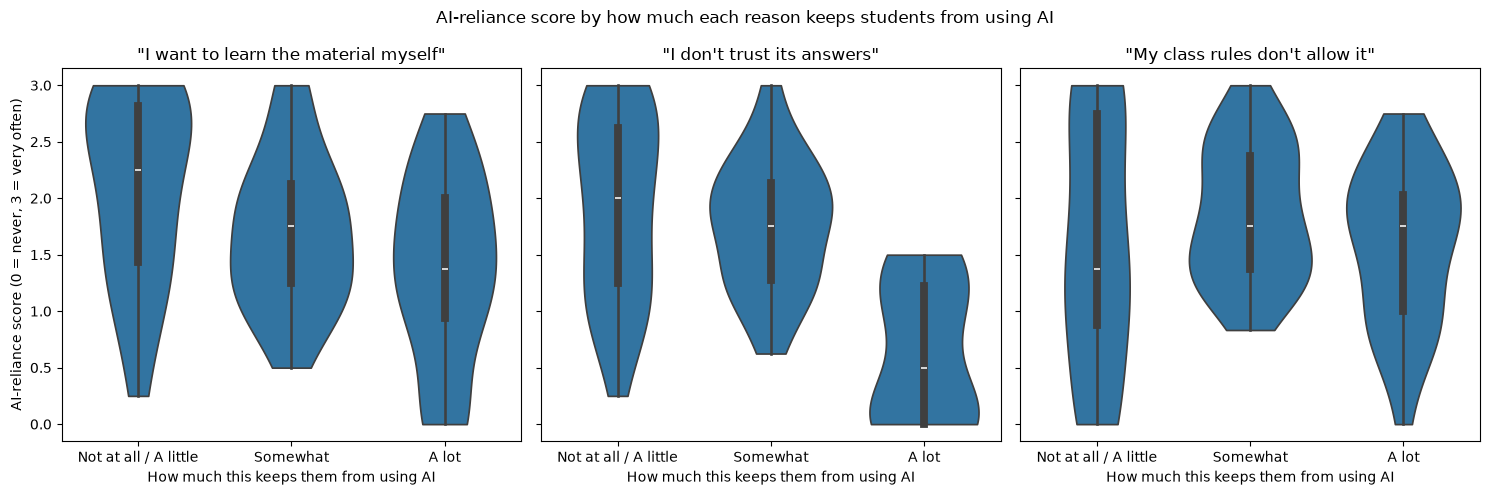

In [10]:
# violin ordering
order = ["Not at all / A little", "Somewhat", "A lot"]

# panel title -> column in data_1
reasons = {
    "I want to learn the material myself": "learn_myself",
    "I don't trust its answers": "no_trust",
    "My class rules don't allow it": "class_rules",
}

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

i = 0
for title, col in reasons.items():
    sns.violinplot(data=data_1, x=col, y="reliance_score", order=order, cut=0, ax=axes[i])
    axes[i].set_title(f'"{title}"')
    axes[i].set_xlabel("How much this keeps them from using AI")

    # number of students and median score for each group
    print(title)
    print(data_1.groupby(col)["reliance_score"].agg(["count", "median"]).loc[order].round(2))
    print()

    i += 1

axes[0].set_ylabel("AI-reliance score (0 = never, 3 = very often)")
fig.suptitle("AI-reliance score by how much each reason keeps students from using AI")
plt.tight_layout()
plt.show()

#### Interpretation

Each panel is one reason, and each violin is a group of students based on how much that reason keeps them from using AI. The height shows their AI-reliance score. For the two reasons that come from the student, it is clear that as we move from left to right the scores drop: wanting to learn the material myself (median 2.25 $\rightarrow$ 1.75 $\rightarrow$ 1.38) and not trusting its answers (2.00 $\rightarrow$ 1.75 $\rightarrow$ 0.50, though only 12 students said "A lot"). For class rules the scores don't drop, if anything they go up slightly (1.38 $\rightarrow$ 1.75 $\rightarrow$ 1.75). What this can tell us is that a student's own reasons line up with how much they use AI, while class rules don't seem to.

### Visualization 2: When students are stressed, do they seek AI over their professor/TA?

#### Plot

ai_instead           Rarely  Sometimes  Often
stress                                       
Less stressed (1-3)      13         17      4
Very stressed (4-5)       7         17     25

ai_instead           Rarely  Sometimes  Often
stress                                       
Less stressed (1-3)    38.0       50.0   12.0
Very stressed (4-5)    14.0       35.0   51.0

Squares out of 100:
ai_instead           Rarely  Sometimes  Often
stress                                       
Less stressed (1-3)      38         50     12
Very stressed (4-5)      14         35     51


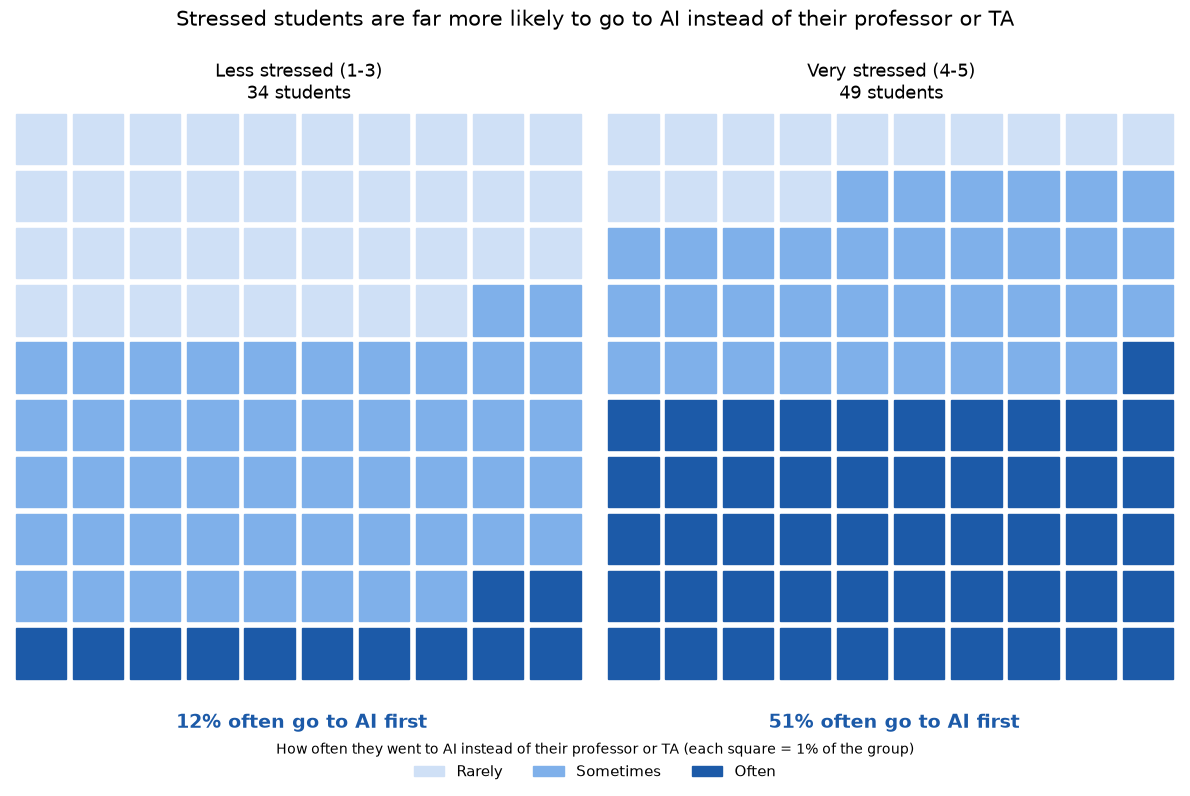


Understanding a course concept: Less stressed (1-3) 26%, Very stressed (4-5) 65%
Understanding what an assignment is asking: Less stressed (1-3) 12%, Very stressed (4-5) 31%
Figuring out how to solve a problem: Less stressed (1-3) 9%, Very stressed (4-5) 41%


In [11]:
# order
stress_order = ["Less stressed (1-3)", "Very stressed (4-5)"]
ai_order = ["Rarely", "Sometimes", "Often"]

# lighter = less AI, darker = more AI
colors = {"Rarely": "#cfe0f6", "Sometimes": "#7fb0ea", "Often": "#1c5aa8"}

# number and percent of students in each group
table = pd.crosstab(data_2["stress"], data_2["ai_instead"]).loc[stress_order, ai_order]
percent = (table.div(table.sum(axis=1), axis=0) * 100).round(0)
print(table)
print()
print(percent)

# both groups get a 10 x 10 grid, so each square is 1% of that group
columns = 10
rows = 10

# turn each group's percents into 100 whole squares
# round down first, then give any leftover squares to the answers that lost the most from rounding
square_counts = percent.copy()
for group in stress_order:
    exact = table.loc[group] / table.loc[group].sum() * 100
    whole = exact.astype(int)
    leftover = 100 - whole.sum()
    biggest_remainders = (exact - whole).sort_values(ascending=False).index[:leftover]
    whole[biggest_remainders] += 1
    square_counts.loc[group] = whole
square_counts = square_counts.astype(int)
print()
print("Squares out of 100:")
print(square_counts)

fig, axes = plt.subplots(1, 2, figsize=(12, 8))

i = 0
for group in stress_order:
    ax = axes[i]

    # 100 squares, Rarely first and Often last so each color is one block
    squares = []
    for answer in ai_order:
        squares += [answer] * square_counts.loc[group, answer]

    # fill left to right, top to bottom
    for n, answer in enumerate(squares):
        x = n % columns
        y = rows - 1 - n // columns
        ax.add_patch(Rectangle((x, y), 0.88, 0.88, color=colors[answer]))

    ax.set_xlim(-0.1, columns)
    ax.set_ylim(-0.1, rows)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(f"{group}\n{table.loc[group].sum()} students", fontsize=13)

    # the one number to remember, under each grid
    often = percent.loc[group, "Often"]
    ax.text(columns / 2, -0.6, f"{often:.0f}% often go to AI first", ha="center", va="top",
            fontsize=14, fontweight="bold", color=colors["Often"])

    i += 1

legend = [Patch(color=colors[a], label=a) for a in ai_order]
fig.legend(handles=legend, loc="lower center", ncol=3, frameon=False, fontsize=11,
           title="How often they went to AI instead of their professor or TA (each square = 1% of the group)",
           bbox_to_anchor=(0.5, 0))
fig.suptitle("Stressed students are far more likely to go to AI instead of their professor or TA", fontsize=15)
# leave room at the top for the title and at the bottom for the legend
plt.tight_layout(rect=[0, 0.1, 1, 0.94])
plt.show()

# same thing for each task on its own: percent who said Often or All the time
print()
for col in skip_cols_2:
    task = col.split("[")[-1].strip("]")
    answered = pd.DataFrame({"stress": stress_2, "answer": numbers_2[col]}).dropna()
    often_pct = (answered["answer"] >= 3).groupby(answered["stress"], observed=True).mean() * 100
    print(f"{task}: " + ", ".join(f"{g} {p:.0f}%" for g, p in often_pct.loc[stress_order].items()))

#### Interpretation

Each grid is one group of students (less stressed / stressed) scaled to 100 squares so they can be compared directly. The darker the square the more often students went to AI instead of their professor/TA. The less stressed group had 34 students and only about 12 out of every 100 often went to AI first. In the stressed group there are 49 students, the dark block takes up half the grid telling us that 51 out of every 100 students often go to AI first. What this can tell us is that when students are stressed, AI replaces their professor or TA. This suggests that pressure, and not just convenience, is one reason some students use AI more than others.

### Visualization 3: Does Procrastination lead to more AI use

#### Plot

In [12]:
sankey_data = df_sankeyAnalysis_3[["reliance_after_procrastinating","ai_days","main_reason"]].copy()


sankey_data = sankey_data.dropna(subset=["reliance_after_procrastinating","ai_days","main_reason"]).copy()


def categorize_days(days):
    if days == 0:
        return "No AI use"
    elif days <= 2:
        return "1 to 2 days"
    elif days <= 4:
        return "3 to 4 days"
    else:
        return "5 to 7 days"

sankey_data["ai_usage"] = sankey_data["ai_days"].apply(categorize_days)


sankey_data["main_reason"] = (sankey_data["main_reason"].astype(str).str.replace(r"Generating answers,\s*text,\s*or code","Generating answers text or code",regex=True,case=False))


sankey_data["main_reason"] = (sankey_data["main_reason"].str.split(r"\s*,\s*"))

sankey_data = sankey_data.explode("main_reason")


sankey_data["main_reason"] = (sankey_data["main_reason"].str.replace("Generating answers text or code", "Generating answers, text, or code",regex=False).str.strip())


conflicts = (sankey_data["main_reason"].str.contains("Did not use AI",case=False,na=False) & (sankey_data["ai_days"] > 0))

print("Conflicting responses:", conflicts.sum())

sankey_data.loc[conflicts, "main_reason"] = "Conflicting responses"


print("Total respondent-reason paths:", len(sankey_data))
print("Unique students:", sankey_data.index.nunique())


reliance_categories = ["Never","Rarely","Sometimes","Often","Always"]

usage_categories = ["No AI use","1 to 2 days","3 to 4 days","5 to 7 days"]

reason_categories = sorted(sankey_data["main_reason"].unique())


nodes = (["Reliance: " + x for x in reliance_categories] + ["AI Usage: " + x for x in usage_categories] + ["Reason: " + x for x in reason_categories])

node_ids = {label: i for i, label in enumerate(nodes)}

sources = []
targets = []
values = []


def add_connections(source_col,target_col,source_prefix,target_prefix):
    grouped = (sankey_data.groupby([source_col, target_col]).size().reset_index(name="count"))

    for _, row in grouped.iterrows():
        source = source_prefix + str(row[source_col])
        target = target_prefix + str(row[target_col])
        sources.append(node_ids[source])
        targets.append(node_ids[target])
        values.append(row["count"])


add_connections("reliance_after_procrastinating","ai_usage","Reliance: ","AI Usage: ")


add_connections("ai_usage","main_reason","AI Usage: ","Reason: ")


fig = go.Figure(data=[go.Sankey(arrangement="snap",node=dict(pad=25,thickness=22,line=dict(color="black",width=0.5),label=nodes),link=dict(source=sources,target=targets,value=values))])

fig.update_layout(title_text="Student Procrastination, AI Usage, and Individual Motivations",font_size=12,height=800,width=1200)

fig.show()

Conflicting responses: 2
Total respondent-reason paths: 180
Unique students: 78


#### Interpretation

**What we suspect:**

Students who report relying on AI more after they procrastinate will use AI more often throughout the week for schoolwork.

**Our analysis:**

We made a sankey diagram that shows the flow of questions from Procrastination reliance to AI usage per week to what they use it for. It was grouped into three sections of 1-2 days 3-4 days and 5-7 days. The wider the path the more people responded that way.

**Findings:**

Students most commonly say they sometimes or rarely use AI after procrastinating

The weekly usage was mostly in 3-4 days and 5-7 days which shows most of them use AI fairly commonly

People who said Always used AI 5-7 days 100% of the time based on the data


**Conclusion:**
The sankey diagram supports our hypothesis that people who rely on AI after procrastinating will use it more throughout the week for schoolwork. As most of them chose 5-7 days or 3-4 days and very few chose only 1-2 days and the ones who said always relied on it 5-7 days a week 100% of the time.


### Visualization 4: What Do Students Use AI For Most?

#### Plot

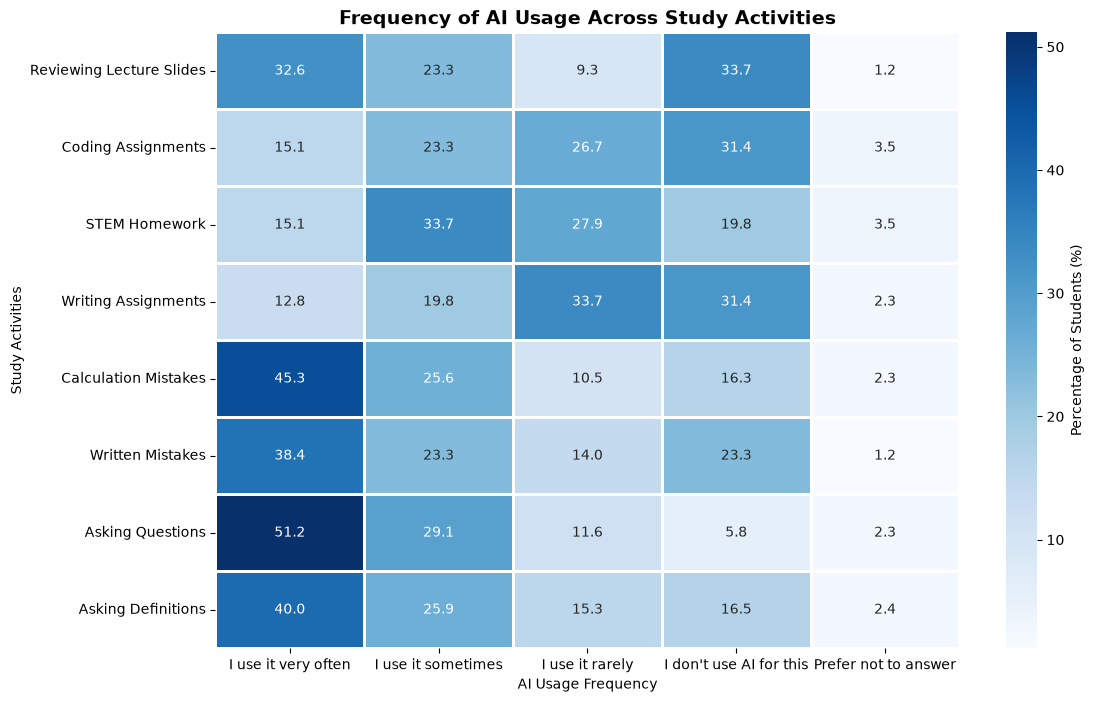

In [13]:
# Create a heatmap
# Set figure size for better readability
plt.figure(figsize=(12, 8))

# cmap='Blues': Darker blue represents a higher percentage
# annot=True: Displays the percentages in each cell
# fmt='.1f': Shows percentages with 1 decimal place
# linewidths=1: Adds spacing between cells
sns.heatmap(percentage_survey_4, cmap='Blues', annot=True, fmt='.1f',
            linewidths=1, cbar_kws={'label': 'Percentage of Students (%)'})

# Add title and labels
plt.title('Frequency of AI Usage Across Study Activities', fontsize=14, fontweight='bold')
plt.xlabel('AI Usage Frequency')
plt.ylabel('Study Activities')
plt.show()

#### Interpretation

**What we suspect:**
We think students are more likely to use AI frequently for asking questions, finding definitions, and reviewing mistakes in their work than for completing coding, STEM homework, or writing-based assignments.

**Our analysis:**
We used responses from eight survey questions about how frequently students use AI for different study activities. Seven activities contain 86 responses each, while asking for definitions contains 85 responses.

We compared the frequency of AI use across these eight study activities. We grouped responses into Very Often, Sometimes, Rarely, Don't Use AI, and Prefer Not to Answer. We then calculated the percentage of students selecting each response and displayed the results using a heatmap.

**Findings:**

- 80.3% of students use AI very often or sometimes for asking questions or clarifying concepts.
- 70.9% use AI very often or sometimes for reviewing calculation mistakes.
- 65.9% use AI very often or sometimes for asking for definitions.
- 48.8% use AI very often or sometimes for STEM homework.
- 38.4% use AI very often or sometimes for completing coding assignments.
- 32.6% use AI very often or sometimes for writing assignments.

**Conclusion:**
Students use AI more frequently for understanding concepts and reviewing mistakes than for completing assignments directly. Asking questions and reviewing calculation mistakes are among the most common uses of AI. The results support our hypothesis.

### Visualization 5: Deadline Pressure and AI Use

#### Plot

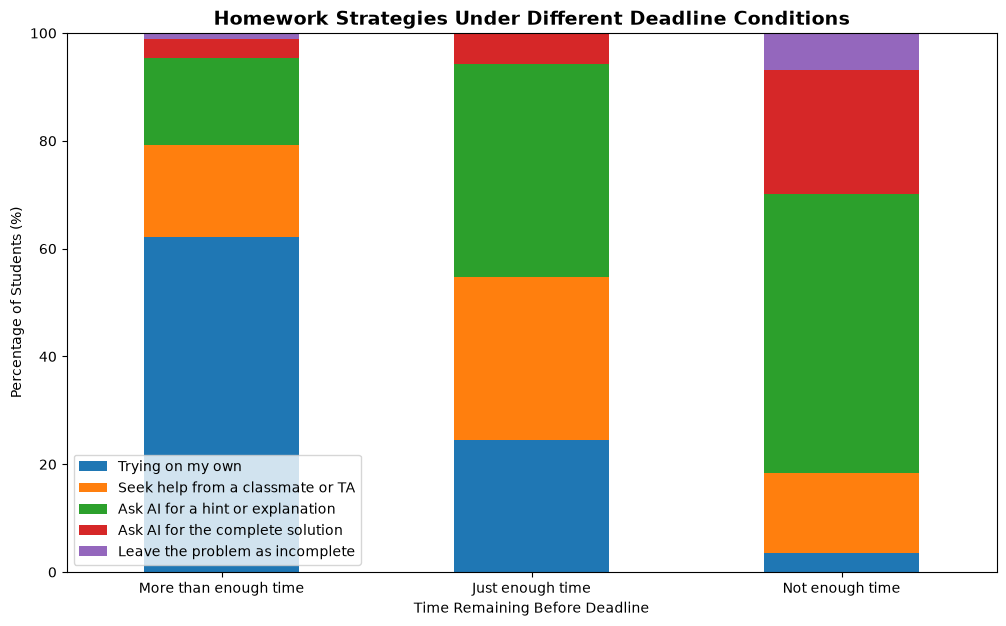

In [14]:
# Create a 100% stacked bar chart to compare homework strategies under different deadline conditions
# Create the stacked bar chart
# stacked=True: Stacks different homework strategies into one bar
# Each bar represents 100% of responses for one deadline situation
percentage_homework_5.plot.bar(stacked=True, figsize=(12, 7))

# Add title and axis labels
plt.title('Homework Strategies Under Different Deadline Conditions', fontsize=14, fontweight='bold')
plt.xlabel('Time Remaining Before Deadline')
plt.ylabel('Percentage of Students (%)')

# Set the y-axis range from 0% to 100%
plt.ylim(0, 100)

# Rotate x-axis labels for readability
plt.xticks(rotation=0)

# Display the chart
plt.show()

#### Interpretation

If you have been working on a homework problem for 15 minutes without making any progress, what action are you most likely to take when you have more than enough time, just enough time, or not enough time before the deadline?

**What we suspect:**

We think students are more likely to ask AI for hints, explanations, or complete solutions as deadline pressure increases, rather than continuing to solve problems independently.

**Our analysis:**

We compared students' preferred homework strategies under three different deadline scenarios. We calculated the percentage of students choosing each strategy and displayed the results using a 100% stacked bar chart to show how the distribution of responses changes as available time decreases.

**Findings:**

- When students have more than enough time, 19.5% prefer AI assistance.
- When students have just enough time, 45.3% prefer AI assistance.
- When students do not have enough time, 74.7% prefer AI assistance.
- The percentage choosing to work independently decreases from 62.1% to 3.4% between the first and last scenarios.

**Conclusion:**

Students are increasingly likely to choose AI assistance as deadline pressure increases. The results suggest an association between having less time to complete homework and a greater preference for AI assistance.

### Visualization 6: Does AI Reduce Stress Relative to Minutes Using AI

#### Plot

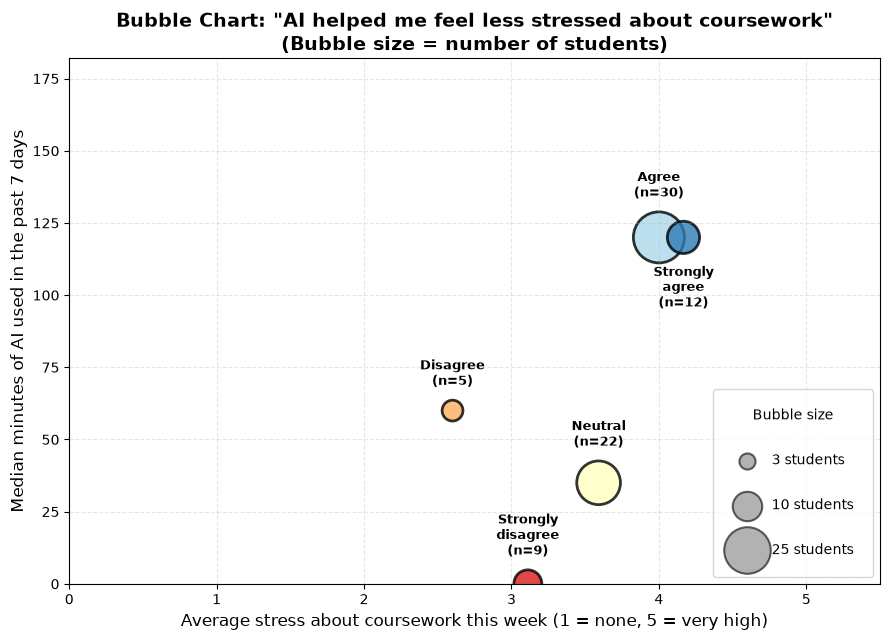

In [15]:
SCALE = 45

plt.figure(figsize=(9, 6.5))
plt.scatter(stress_avg_6, minutes_med_6,
            s=[n * SCALE for n in students_6],
            c=bubble_colors_6,
            alpha=0.8,
            edgecolors="black",
            linewidth=2)


below = {5}
for g, lab, n, x_, y_ in zip(groups_6, labels_6, students_6, stress_avg_6, minutes_med_6):
    offset = np.sqrt(n * SCALE) / 2 + 8
    if int(g) in below:
        plt.annotate(f"{lab}\n(n={n})", (x_, y_), xytext=(0, -offset), textcoords="offset points",
                     ha="center", va="top", fontweight="bold", fontsize=9)
    else:
        plt.annotate(f"{lab}\n(n={n})", (x_, y_), xytext=(0, offset), textcoords="offset points",
                     ha="center", va="bottom", fontweight="bold", fontsize=9)

plt.xlabel("Average stress about coursework this week (1 = none, 5 = very high)", fontsize=12)
plt.ylabel("Median minutes of AI used in the past 7 days", fontsize=12)
plt.title('Bubble Chart: "AI helped me feel less stressed about coursework"\n'
          "(Bubble size = number of students)", fontsize=14, fontweight="bold")

plt.grid(True, alpha=0.3, linestyle="--")


plt.xlim(0, 5.5)
plt.xticks(range(0, 6))
plt.ylim(0, max(minutes_med_6) * 1.35 + 20)


legend_sizes = [3, 10, 25]
legend_elements = [plt.scatter([], [], s=v * SCALE, c="gray", alpha=0.6, edgecolors="black",
                               linewidth=1.5, label=f"{v} students") for v in legend_sizes]
plt.legend(handles=legend_elements, title="Bubble size", loc="lower right",
           labelspacing=2.2, borderpad=1.4, frameon=True)

plt.tight_layout()
plt.show()

#### Interpretation

**Description:**
This bubble chart compares how stressed students are, how many minutes they used AI, and whether they feel AI helped them with stress, with each bubble representing a group of students who gave the same answer to "During this week, AI has helped me feel less stressed/anxious about my coursework" (strongly disagree, disagree, neutral, agree, strongly agree). The graph aims to compare the overall stress students may be feeling and seeing how AI might help reduce that stress. In doing so, students might be more inclined to use AI if it helps them both manage schoolwork and reduce stressful situations.
Note that Median was used over Mean due to a number of outliers in the data set

**Hypothesis:**
Students who feel that AI helps reduce stress while doing schoolwork are more likely to use AI, and students who are more stressed during the week are more likely to feel that AI helps them. Students who disagree that AI reduces their stress use AI the least.


**Analysis:**
53 students answered both the AI-and-stress question and the minutes question. 
33 of them (62%) agreed or strongly agreed that AI helped them feel less stressed, 15 were neutral, and only 5 disagreed or strongly disagreed. 
The Agree group (23 students) and Strongly Agree group (10 students) each have a median of 120 minutes of AI use, three times the Neutral group's median of 40 minutes (15 students). 
This directly shows that students who believed that AI reduced workload stress tended to use it more. 
Although this might not have been the only factor contributing to the increase of AI usage, there is a strong correlation in the visualization that implies that it could have influenced it.

**Conclusion:**
Students who agree that AI helps them feel less stressed use AI more than students who feel neutral about it. 
The more a student agrees that AI makes their schoolwork less stressful the more minutes they tend to have using AI. 
The groups who disagree are too small to draw any sizable conclusions from.

### Visualization 7: Is there a correlation between minutes using AI Relative to Time Spent Procrastinating

#### Plot

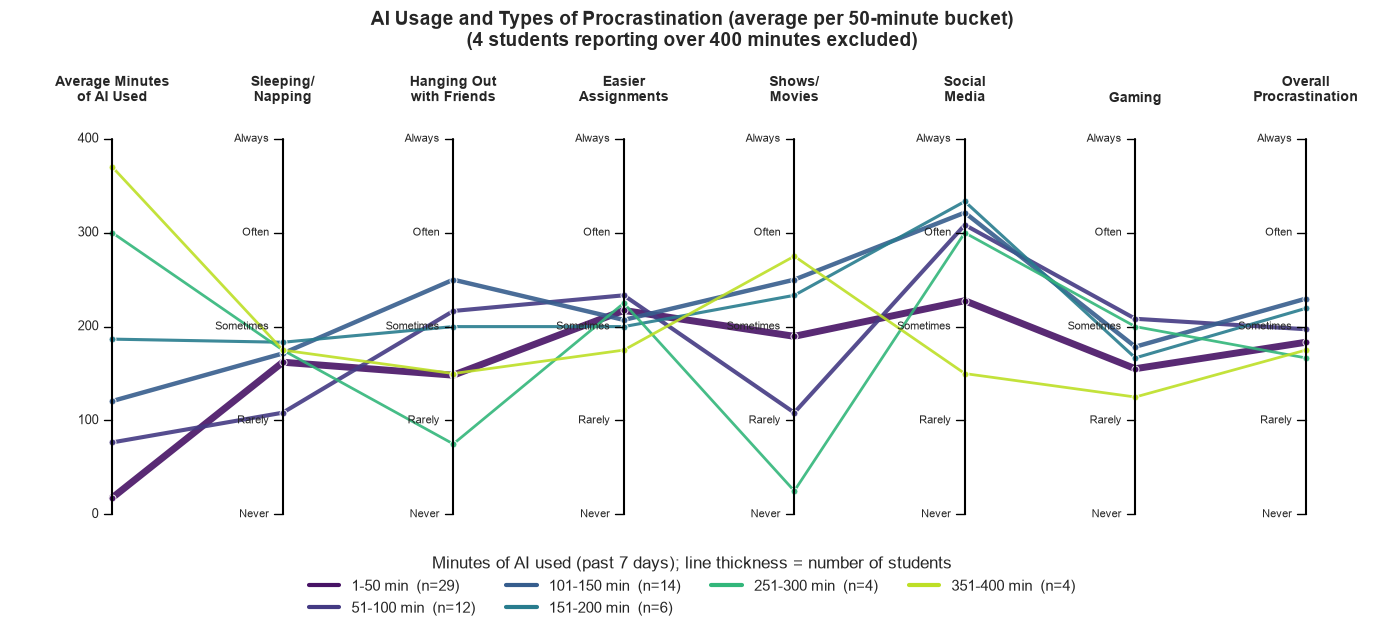

In [16]:
sns.set_theme(style="white", font_scale=1.0)

long_df = (scaled_df_7[columns_7].reset_index().melt(id_vars="bucket", var_name="axis", value_name="value"))
long_df["bucket"] = long_df["bucket"].astype(str)
long_df["x"] = long_df["axis"].map(dict(zip(columns_7, x_7)))

n_max = bucket_n_7.max()
bucket_lw = {str(b): 1.5 + 3.5 * bucket_n_7[b] / n_max for b in bucket_n_7.index}
palette = {str(b): c for b, c in bucket_colors_7.items()}

fig, pcp = plt.subplots(figsize=(14, 6.5))
sns.lineplot(data=long_df, x="x", y="value", hue="bucket", palette=palette,
             size="bucket", sizes=bucket_lw, estimator=None, sort=False,
             marker="o", markersize=5, alpha=0.9, legend=False, ax=pcp)

for xi, col in zip(x_7, columns_7):
    pcp.plot([xi, xi], [0, 1], color="black", linewidth=1.5)
    pcp.text(xi, 1.09, col, ha="center", va="bottom", fontsize=10, fontweight="bold")

for m in ai_ticks_7:
    pos = m / ai_cutoff_7
    pcp.plot([-0.05, 0], [pos, pos], color="black", linewidth=1)
    pcp.text(-0.08, pos, str(m), ha="right", va="center", fontsize=9)

for xi in x_7[1:]:
    for score, label in enumerate(["Never", "Rarely", "Sometimes", "Often", "Always"]):
        pcp.plot([xi - 0.05, xi], [score / 4, score / 4], color="black", linewidth=1)
        pcp.text(xi - 0.08, score / 4, label, ha="right", va="center", fontsize=8)

pcp.set_xlim(-0.6, len(columns_7) - 0.6)
pcp.set_ylim(-0.05, 1.2)
pcp.axis("off")
plt.title(f"AI Usage and Types of Procrastination (average per {bucket_size_7}-minute bucket)\n"
          f"({n_removed_7} students reporting over {ai_cutoff_7} minutes excluded)",
          fontsize=14, fontweight="bold", y=1.02)

legend_handles = [Line2D([0], [0], color=palette[str(b)], lw=3, label=f"{b}  (n={bucket_n_7[b]})") for b in bucket_n_7.index]
pcp.legend(handles=legend_handles, title="Minutes of AI used (past 7 days); line thickness = number of students",
           loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=4, frameon=False)
plt.tight_layout()
plt.show()

#### Interpretation

**Description:**
This parallel coordinate plot compares minutes of AI used with time spent procrastinating with each line representing one student and each axis representing a different type of procrastination: sleeping/napping, hanging out with friends, completing easier or other assignments, watching shows/movies, social media (Instagram, TikTok, etc.), and gaming. Lines that rise or fall together across the axis show which kinds of procrastination tend to go along with heavier or lighter AI use. Where lines cluster tightly, a pattern is shared across students. Where they spread out or cross, the relationship is weaker or varies by person.

**Hypothesis:**
Students who use AI for more minutes spend less time procrastinating overall, and certain types of procrastination, such as completing easier assignments, are less likely to use as much AI as others, such as gaming or social media.


**Analysis:**
We did not find a clear relationship between how much students use AI and how much they procrastinate. 
The lines for different AI-use groups overlap and cross on every axis, with no group consistently higher or lower. 
The differences between the highest buckets come from only 3-4 students each, so they are more likely noise than real patterns. 
What the data does show clearly is that social media is the most common way students procrastinate, regardless of how much they use AI. 
Additionally students who used more AI were very slightly more likely to report procrastinating. 
However, there was too small a sample size to make a clear correlation. 
A larger sample would be needed to rule out a small relationship.

**Conclusion:**
There is no clear relationship between how many minutes students used AI and how they procrastinate. 
AI usage does not appear to depend on how a student procrastinates, but social media is the dominant procrastination activity across all AI usage levels.
It does seem that students who used more AI reported more procrastination, but a larger sample size would be best to verify that.

### Visualization 8: Do AI deterrents differ by year?

#### Plot

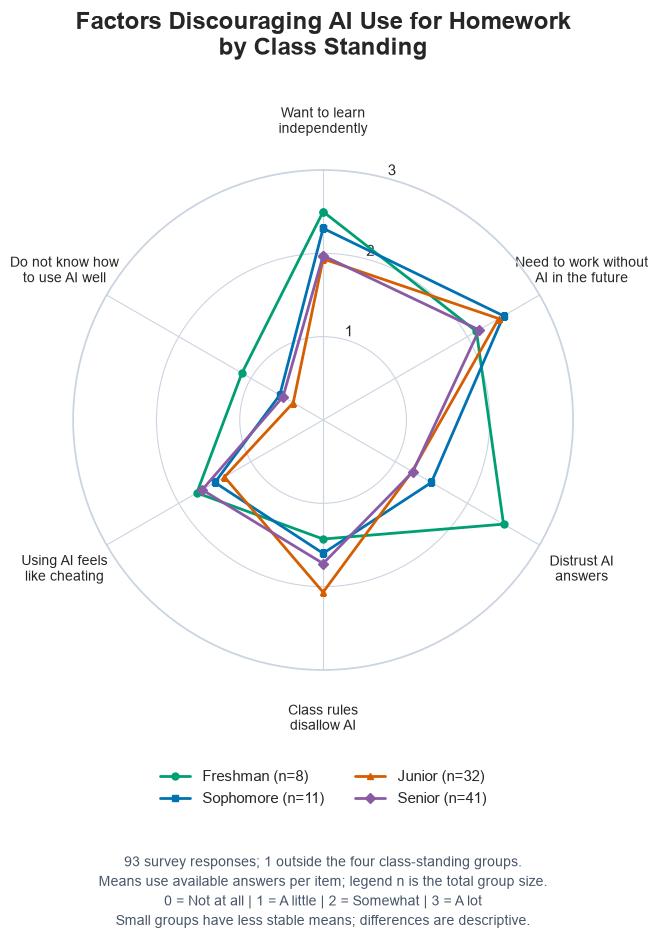

Group mean ratings:
                learn_myself  future_independence  distrust_answers  class_rules  feels_like_cheating  lack_of_ai_skills
class_standing                                                                                                          
Freshman                 2.5                 2.12               2.5         1.43                 1.75               1.12
Sophomore                2.3                  2.5               1.5          1.6                  1.5                0.6
Junior                  1.93                 2.43              1.23         2.07                 1.37               0.41
Senior                  1.97                 2.16              1.24         1.72                 1.68               0.56

Valid responses per group and factor:
                learn_myself  future_independence  distrust_answers  class_rules  feels_like_cheating  lack_of_ai_skills
class_standing                                                                                

In [17]:
order = list(factors_8)
year_order = ['Freshman', 'Sophomore', 'Junior', 'Senior']
# Use row positions because clean_factors_8 is indexed by original Excel row.
class_standing = pd.Series(
    df_8['What is your current class standing?'].astype('string').str.strip().to_numpy(),
    index=clean_factors_8.index, name='class_standing',
)
year_data = clean_factors_8[order].join(class_standing)
year_data = year_data[year_data['class_standing'].isin(year_order)]
year_means = year_data.groupby('class_standing')[order].mean().reindex(year_order)
year_counts = year_data.groupby('class_standing')[order].count().reindex(year_order)
year_sizes = year_data.groupby('class_standing').size().reindex(year_order, fill_value=0)
label_text = [
    'Want to learn\nindependently', 'Need to work without\nAI in the future',
    'Distrust AI\nanswers', 'Class rules\ndisallow AI',
    'Using AI feels\nlike cheating', 'Do not know how\nto use AI well',
]
angles = np.linspace(0, 2 * np.pi, len(order), endpoint=False)
closed_angles = np.r_[angles, angles[0]]
fig, ax = plt.subplots(figsize=(11, 10), subplot_kw={'projection': 'polar'})
fig.subplots_adjust(left=0.20, right=0.80, top=0.80, bottom=0.30)
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_ylim(0, 3)
ax.set_yticks([1, 2, 3])
ax.set_rlabel_position(15)
ax.set_xticks(angles)
ax.set_xticklabels(label_text, fontsize=10)
ax.tick_params(axis='x', pad=22)
ax.grid(color='#cbd5e1', linewidth=0.8)
ax.spines['polar'].set_color('#cbd5e1')
colors = ['#009E73', '#0072B2', '#D55E00', '#8B5AA5']
markers = ['o', 's', '^', 'D']
for year, color, marker in zip(year_order, colors, markers):
    values = year_means.loc[year].astype(float).to_numpy()
    ax.plot(closed_angles, np.r_[values, values[0]], color=color,
            marker=marker, linewidth=2, markersize=5,
            label=f'{year} (n={year_sizes[year]})')
fig.suptitle('Factors Discouraging AI Use for Homework\nby Class Standing',
             fontsize=17, fontweight='bold', y=0.96)
fig.legend(*ax.get_legend_handles_labels(), loc='lower center',
           bbox_to_anchor=(0.5, 0.15), ncol=2, frameon=False)
excluded_year_n = len(df_8) - len(year_data)
fig.text(0.5, 0.045,
         f'{len(df_8)} survey responses; {excluded_year_n} outside the four class-standing groups.\n'
         'Means use available answers per item; legend n is the total group size.\n'
         '0 = Not at all | 1 = A little | 2 = Somewhat | 3 = A lot\n'
         'Small groups have less stable means; differences are descriptive.',
         ha='center', fontsize=10, color='#475569', linespacing=1.5)
radar_path = output_dir_8 / 'deterrents_radar.png'
fig.savefig(radar_path, dpi=200, facecolor='white')
plt.show()
plt.close(fig)
print('Group mean ratings:')
print(year_means.round(2).to_string())
print('\nValid responses per group and factor:')
print(year_counts.to_string())
print('\nSaved:', radar_path.name)

#### Interpretation

**What we want to learn:** How do the six deterrents differ across years?

Each color and marker represents a year. Lines show mean scores on the same 0–3 scale. The legend gives group sizes, and the output gives valid counts per item. The chart excludes one concurrent student whose year is unclear.

**Interpretation:** Future independence had the highest mean for sophomores (2.50), juniors (2.43), and seniors (2.16). For freshmen, independent learning and distrust of AI tied at 2.50. Difficulty using AI had the lowest mean in every group.

Freshman (n=8) and sophomore (n=11) groups are small. The chart describes differences; year-group significance has not been tested.

## II. Formulating and Testing Hypotheses

### Hypothesis 1: Students who use AI for asking questions also use it for reviewing calculation mistakes

**Based on:** Visualization 4 (What Do Students Use AI For Most?)

**What we suspect:** We think students who frequently use AI for asking questions and clarifying concepts are also more likely to use AI frequently for reviewing calculation mistakes.

**H₀:** There is no monotonic correlation between how frequently students use AI for asking questions and reviewing calculation mistakes.

**H₁:** There is a monotonic correlation between the two activities.

#### Test

**Test and justification:** We used Spearman's rank correlation to test the relationship between these two study activities because the responses are ordered categories. Significance level: 0.05.

**Data used:** We converted the frequency responses into numerical values from 0 to 3, where 0 means "I don't use AI for this" and 3 means "I use it very often." We excluded missing responses and students who preferred not to answer. Valid paired responses: 83.

In [18]:
# Convert frequency responses into numerical values
frequency_scale = {
    "I don't use AI for this": 0,
    "I use it rarely": 1,
    "I use it sometimes": 2,
    "I use it very often": 3
}

# Select the two activities from study_df_4
questions_score = study_df_4.iloc[:, 6].map(frequency_scale)
calculation_score = study_df_4.iloc[:, 4].map(frequency_scale)

# Combine responses and remove missing values
correlation_df = pd.DataFrame({
    "Asking Questions": questions_score,
    "Reviewing Calculation Mistakes": calculation_score
}).dropna()

# Perform Spearman correlation test
rho, p_value = spearmanr(
    correlation_df["Asking Questions"],
    correlation_df["Reviewing Calculation Mistakes"]
)

print(f"Sample size: {len(correlation_df)}")
print(f"Spearman correlation: {rho:.3f}")
print(f"P-value: {p_value:.4f}")

Sample size: 83
Spearman correlation: 0.585
P-value: 0.0000


#### Result

- Statistic: Spearman correlation coefficient ρ = 0.585
- p-value: p < 0.0001
- Decision: Since the p-value is smaller than 0.05, we reject the null hypothesis. The correlation is positive and statistically significant.

**Conclusion:** The results indicate a statistically significant, moderate positive correlation between students' frequency of using AI for asking questions and reviewing calculation mistakes. This suggests that students who frequently use AI for one activity also tend to use it frequently for the other, but it does not prove causation.

### Hypothesis 2: Students who rely on AI after procrastinating use AI more days per week

**Based on:** Visualization 3 (Does Procrastination lead to more AI use)

**What we suspect:** We think students who report relying on AI more after procrastinating are also more likely to use AI frequently throughout the week for schoolwork.

**H₀:** There is no correlation between how often students rely on AI after procrastinating and how many days they use AI for schoolwork.

**H₁:** There is a correlation between the two variables.

#### Test

**Test and justification:** We used Spearman's correlation to test because the responses are ordered categories. Significance level: 0.05.

**Data used:** Converted the responses about relying on AI after procrastinating into numerical values from 1 to 5. Used the number of days each student reported using AI for schoolwork during the past week of 0-7 days. Valid paired responses: 79.

In [19]:
correlation_data = df_sankeyAnalysis_3[["reliance_after_procrastinating", "ai_days"]].copy()

reliance_mapping = {"Never": 1,"Rarely": 2,"Sometimes": 3,"Often": 4,"Always": 5}

correlation_data["reliance_score"] = (correlation_data["reliance_after_procrastinating"].map(reliance_mapping))

correlation_data = correlation_data.dropna(subset=["reliance_score", "ai_days"])

correlation, p_value = spearmanr(correlation_data["reliance_score"],correlation_data["ai_days"])

print("Number of students:", len(correlation_data))
print("Spearman correlation:", correlation)
print("P-value:", p_value)

Number of students: 79
Spearman correlation: 0.3999209103290754
P-value: 0.0002606616483364887


#### Result

- Statistic: Spearman correlation coefficient ρ = 0.3999
- p-value: 0.000261
- Decision: Since the p-value is smaller than 0.05 we reject the null hypothesis. The correlation is positive and statistically significant.

**Conclusion:** The results indicate a moderate positive correlation between how often students rely on AI after procrastinating and how many days they use AI for schoolwork. This suggests that students who report relying on AI more after procrastinating also tend to use AI more frequently throughout the week. But this does not mean that procrastination causes students to use AI more frequently.

### Hypothesis 3: Class-rule and cheating-related deterrents are associated

**Based on:** Visualization 8 (Do AI deterrents differ by year?)

**What we suspect:** We think students who say class rules keep them from using AI are also more likely to say that feeling like they are cheating keeps them from using AI.

**H₀:** The two deterrents are independent.

**H₁:** The two deterrents are associated.

#### Test

**Test and justification:** Use a 2 × 2 chi-squared independence test with Yates correction at α = 0.05. Include respondents who answered both items. Each respondent enters one cell, and all expected counts must be at least 5. Responses are assumed independent.

**Data used:** Lower = Not at all / A little. Higher = Somewhat / A lot. This split separates weaker and stronger barriers but loses detail. The class-rule item measures a reported barrier, not the actual course policy. Complete responses: 84.

In [20]:
chi_answers = clean_factors_8[['class_rules', 'feels_like_cheating']].dropna()
chi_group_map = {0: 'Lower deterrence', 1: 'Lower deterrence',
                 2: 'Higher deterrence', 3: 'Higher deterrence'}
chi_groups = chi_answers.apply(lambda column: column.map(chi_group_map))
chi_levels = ['Lower deterrence', 'Higher deterrence']
chi_observed = pd.crosstab(
    chi_groups['class_rules'], chi_groups['feels_like_cheating'],
).reindex(index=chi_levels, columns=chi_levels, fill_value=0)
chi_observed.index.name = 'Class-rule deterrence'
chi_observed.columns.name = 'Cheating-related deterrence'
if (chi_observed.sum(axis=0) == 0).any() or (chi_observed.sum(axis=1) == 0).any():
    raise ValueError('Both deterrence groups must be represented for each item.')
chi_statistic, chi_p_value, chi_dof, chi_expected_array = stats.chi2_contingency(
    chi_observed, correction=True,
)
chi_expected = pd.DataFrame(
    chi_expected_array, index=chi_observed.index, columns=chi_observed.columns,
)
if (chi_expected_array < 5).any():
    raise ValueError('Expected cell counts are below 5; reassess the chi-squared method.')
chi_higher_percent = 100 * chi_observed['Higher deterrence'] / chi_observed.sum(axis=1)
print(f'Complete responses: {len(chi_answers)}; excluded: {len(df_8) - len(chi_answers)}')
print('Observed counts (rows = class rules; columns = cheating):')
print(chi_observed.to_string())
print('\nExpected counts:')
print(chi_expected.round(2).to_string())
print(f'\nPearson chi-squared with Yates correction: chi2({chi_dof}) = '
      f'{chi_statistic:.4f}, p = {chi_p_value:.6g}')
print('\nHigher cheating-related deterrence within each class-rule group (%):')
print(chi_higher_percent.round(1).to_string())

Complete responses: 84; excluded: 9
Observed counts (rows = class rules; columns = cheating):
Cheating-related deterrence  Lower deterrence  Higher deterrence
Class-rule deterrence                                           
Lower deterrence                           22                  7
Higher deterrence                          19                 36

Expected counts:
Cheating-related deterrence  Lower deterrence  Higher deterrence
Class-rule deterrence                                           
Lower deterrence                        14.15              14.85
Higher deterrence                       26.85              28.15

Pearson chi-squared with Yates correction: chi2(1) = 11.3720, p = 0.000745598

Higher cheating-related deterrence within each class-rule group (%):
Class-rule deterrence
Lower deterrence     24.1
Higher deterrence    65.5


#### Result

- Statistic: χ²(1) = 11.37, with Yates correction
- p-value: p = 0.000746
- Decision: All expected counts exceeded 5. Reject H₀ at α = 0.05.

**Conclusion:** Among 84 complete responses, higher cheating-related deterrence was reported by 65.5% of the higher class-rule group and 24.1% of the lower group. The two reported barriers are associated in this sample. This exploratory analysis does not establish causation.

## Overall Conclusion

Our main question was why some students use AI more than others: is it pressure, convenience, or what holds them back? Pressure stood out the most. As deadlines got closer, the share of students choosing AI rose from 19.5% to 74.7%, stressed students were far more likely to go to AI before their professor or TA (51% vs. 12%), and students who rely on AI after procrastinating used it on more days each week. What holds students back also mattered, but mainly when the reason was their own: students who want to learn the material themselves or don't trust AI's answers used it less, while class rules did not seem to lower use. Most students also use AI as a learning tool, mainly for asking questions and reviewing mistakes rather than completing assignments. Not every factor mattered, though: how students procrastinate showed no clear link to how much they use AI. Since these results come from a single survey of about 90 students, they show associations, not causation.

## Group Contributions

| Member | Contribution |
|---|---|
| jcarb044 | 20% |
| jprad022 | 20% |
| jyu356 | 20% |
| kaung006 | 20% |
| slian088 | 20% |

Jorge Carbajal: Visualization 1 and 2; Putting the notebook together.  

Jovanni Prado: Visualization 3, Hypothesis 2, Putting notebook together.  

Junwen Yu: Heatmap (visualization 4) and 100% stacked bar chart(visualization 5). Cleaned and analyzed the survey data for both visualizations, performed a Spearman correlation test, and wrote the structure for the project's overall conclusion.  

Khant Aung: Visual 6 and Visual 7.  

Shiyao Liang: Visualization 8 and chi squared test.